# Hi-C Window Normalization Comparison

This notebook visualizes and compares different normalization methods for Hi-C windows:
- **raw**: Raw Hi-C contacts (gap bins masked as NaN)
- **iced**: ICE normalized contacts
- **ln(o/e)**: Log ratio of observed over expected
- **fill_gap**: Gap-filled ln(o/e) with NaN replaced by 0
- **z-score**: Distance-stratified z-score
- **gaussian**: Gaussian smoothed z-score

Gap bins in the raw matrix are read from the gaps file and masked as NaN (white/transparent in plots).

In [1]:
import os
import sys
import h5py
import json
import warnings
import numpy as np
import pandas as pd
import cooler
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize
import seaborn as sns
from scipy.ndimage import gaussian_filter

# Ignore warnings
warnings.filterwarnings('ignore')

# Configuration
OUTDIR = "results"

# Working directory (all paths relative to this)
WORKDIR = "/share/home/xhhuang24/project/PanTE/background_pool"
os.chdir(WORKDIR)
print(f"Working directory: {WORKDIR}")
print(f"Results directory: {os.path.join(WORKDIR, OUTDIR)}")

# Path helpers
raw_dir = os.path.join(WORKDIR, OUTDIR, "raw")
balanced_dir = os.path.join(WORKDIR, OUTDIR, "balanced")
windows_dir = os.path.join(WORKDIR, OUTDIR, "windows")
print(f"Raw data directory: {raw_dir}")
print(f"Balanced data directory: {balanced_dir}")
print(f"Windows directory: {windows_dir}")

Working directory: /share/home/xhhuang24/project/PanTE/background_pool
Results directory: /share/home/xhhuang24/project/PanTE/background_pool/results
Raw data directory: /share/home/xhhuang24/project/PanTE/background_pool/results/raw
Balanced data directory: /share/home/xhhuang24/project/PanTE/background_pool/results/balanced
Windows directory: /share/home/xhhuang24/project/PanTE/background_pool/results/windows


In [2]:
# ================================================================
# Window Selection Configuration
# ================================================================
# METHOD 1: Select by window ID
SAMPLE = "L128_rep1"
CHROM = "HC04_A01"
WINDOW_ID = 11          # window ID (0-based index)
WIN_START = None        # set to None when using WINDOW_ID
WIN_END = None          # set to None when using WINDOW_ID

# METHOD 2: Select by genomic interval (comment out METHOD 1 above)
# SAMPLE = "L128_rep1"
# CHROM = "HC04_A01"
# WINDOW_ID = None       # MUST be None for interval mode
# WIN_START = 1000000     # start position in bp
# WIN_END = 1100000       # end position in bp
# ================================================================

RESOLUTION = 4000

In [3]:
def list_sample_chroms():
    """
    List available sample-chromosome pairs from raw directory.
    Returns list of (sample, chrom) tuples.
    """
    raw_dir = os.path.join(WORKDIR, OUTDIR, "raw")
    pairs = []
    for f in os.listdir(raw_dir):
        if f.endswith(".raw.cool"):
            base = f.replace(".raw.cool", "")
            parts = base.split("__")
            if len(parts) == 2:
                sample, chrom = parts
                pairs.append((sample, chrom))
    return sorted(pairs, key=lambda x: (x[0], x[1]))


sample_chroms = list_sample_chroms()
print(f"Available sample-chromosome pairs ({len(sample_chroms)}):")
for s, c in sample_chroms[:5]:
    print(f"  - {s} | {c}")
if len(sample_chroms) > 5:
    print(f"  ... and {len(sample_chroms) - 5} more")

Available sample-chromosome pairs (0):


In [4]:
# --- Load QC file ---
sample_chrom = f"{SAMPLE}__{CHROM}"
sample_dir = os.path.join(WORKDIR, OUTDIR, "windows", SAMPLE)
qc_file = os.path.join(sample_dir, f"{sample_chrom}_window_qc.tsv")
qc_df = pd.read_csv(qc_file, sep="\t", index_col=0)
print(f"[Config] Sample: {SAMPLE} | Chrom: {CHROM}")
print(f"[Config] Loaded {len(qc_df)} windows from {qc_file}")

# --- Select window ---
if WINDOW_ID is not None:
    # METHOD 1: by ID
    if WINDOW_ID >= len(qc_df):
        raise ValueError(f"Window ID {WINDOW_ID} out of range (max: {len(qc_df)-1})")
    window_info = qc_df.iloc[WINDOW_ID]
    WINDOW_ID = int(WINDOW_ID)
    print(f"[Select] By ID: window {WINDOW_ID}, range {window_info['window_start']:,}-{window_info['window_end']:,} bp")
else:
    # METHOD 2: by interval — find best IoU match
    if WIN_START is None or WIN_END is None:
        raise ValueError("WIN_START and WIN_END must be provided when WINDOW_ID is None")
    if WIN_START >= WIN_END:
        raise ValueError(f"Invalid interval: WIN_START ({WIN_START}) >= WIN_END ({WIN_END})")

    req_len = WIN_END - WIN_START
    best_iou = -1
    best_idx = None
    best_info = None

    for idx, (_, row) in enumerate(qc_df.iterrows()):
        ws, we = row['window_start'], row['window_end']
        overlap = max(0, min(WIN_END, we) - max(WIN_START, ws))
        union = (WIN_END - WIN_START) + (we - ws) - overlap
        iou = overlap / union if union > 0 else 0
        if iou > best_iou:
            best_iou = iou
            best_idx = idx
            best_info = row

    WINDOW_ID = int(best_idx)
    window_info = best_info

    print(f"[Select] By interval: {WIN_START:,}-{WIN_END:,} bp")
    print(f"  -> Best match: window {WINDOW_ID}, range {window_info['window_start']:,}-{window_info['window_end']:,} bp, IoU={best_iou:.3f}")

    # IoU threshold check
    if best_iou < 0.5:
        raise ValueError(
            f"Interval [{WIN_START:,}-{WIN_END:,}] has IoU={best_iou:.3f} with best window {WINDOW_ID} "
            f"(threshold: 0.5). Please adjust your interval or use WINDOW_ID directly."
        )

print(f"[Ready] Window {WINDOW_ID} | {window_info['window_start']:,}-{window_info['window_end']:,} bp")
print(f"[Info] n_gaps={window_info['n_gaps']}, status={window_info['status']}")

[Config] Sample: L128_rep1 | Chrom: HC04_A01
[Config] Loaded 3731 windows from /share/home/xhhuang24/project/PanTE/background_pool/results/windows/L128_rep1/L128_rep1__HC04_A01_window_qc.tsv
[Select] By ID: window 11, range 352,000-652,000 bp
[Ready] Window 11 | 352,000-652,000 bp
[Info] n_gaps=8, status=FAIL_NZ_FRAC


In [5]:
def load_window_data(sample, chrom, window_id_or_info, resolution=RESOLUTION):
    """
    Load window matrices for all normalization types.
    Gap bins in the raw matrix are masked as NaN using the gaps file.

    Args:
        sample: sample name
        chrom: chromosome name
        window_id_or_info: either window_id (int) or window_info (pd.Series from QC df)
        resolution: bin resolution (default from global RESOLUTION)
    """
    sample_chrom = f"{sample}__{chrom}"

    # Handle both int and Series input
    if isinstance(window_id_or_info, int):
        window_id = window_id_or_info
        window_info = None
    else:
        window_info = window_id_or_info
        window_id = int(window_info['window_id'])

    window_key = f"w{window_id:06d}"

    # 文件现在存储在 {sample}/ 子目录下
    sample_dir = os.path.join(WORKDIR, OUTDIR, "windows", sample)

    # HDF5 files for ln_oe, fill_gap, zscore, gaussian
    # Stored in results/windows/{sample}/{sample}__{chrom}_{type}.h5
    h5_files = {
        'ln_oe': os.path.join(sample_dir, f"{sample_chrom}_ln_oe.h5"),
        'fill_gap': os.path.join(sample_dir, f"{sample_chrom}_gap_filled.h5"),
        'zscore': os.path.join(sample_dir, f"{sample_chrom}_zscore.h5"),
        'gaussian': os.path.join(sample_dir, f"{sample_chrom}_gaussian.h5"),
    }

    data = {}

    # Load HDF5 files
    for name, full_path in h5_files.items():
        if os.path.exists(full_path):
            with h5py.File(full_path, 'r') as f:
                if window_key in f:
                    data[name] = f[window_key]['matrix'][:]

    # Get window coordinates
    qc_file = os.path.join(sample_dir, f"{sample_chrom}_window_qc.tsv")
    qc_df = pd.read_csv(qc_file, sep="\t", index_col=0)

    if window_info is None:
        window_info = qc_df.iloc[window_id]

    bin_start = int(window_info['bin_start'])
    bin_end = int(window_info['bin_end'])

    # Raw cool file
    raw_path = os.path.join(WORKDIR, OUTDIR, "raw", f"{sample_chrom}.raw.cool")
    if os.path.exists(raw_path):
        c = cooler.Cooler(raw_path)
        try:
            mat = c.matrix(balance=False, sparse=False)[bin_start:bin_end, bin_start:bin_end].astype(np.float64)
            # Mask gap bins with NaN using gaps file
            # gaps file uses genomic coords; convert to local bin index
            gaps_file = os.path.join(sample_dir, f"{sample_chrom}_gaps.tsv")
            if os.path.exists(gaps_file):
                gaps_df = pd.read_csv(gaps_file, sep="\t")
                win_gaps = gaps_df[
                    (gaps_df['window_id'] == window_id)
                ]
                for _, gap_row in win_gaps.iterrows():
                    # bin_start in gaps file is genomic coord; convert to local bin index
                    local_bin = (int(gap_row['bin_start']) - int(window_info['window_start'])) // resolution
                    if 0 <= local_bin < mat.shape[0]:
                        mat[local_bin, :] = np.nan
                        mat[:, local_bin] = np.nan
            data['raw'] = mat
        except Exception as e:
            print(f"Error loading raw: {e}")

    # ICED cool file
    iced_path = os.path.join(WORKDIR, OUTDIR, "balanced", f"{sample_chrom}_iced.cool")
    if os.path.exists(iced_path):
        c = cooler.Cooler(iced_path)
        try:
            mat = c.matrix(balance=True, sparse=False)[bin_start:bin_end, bin_start:bin_end]
            data['iced'] = mat
        except Exception as e:
            print(f"Error loading iced: {e}")

    return data


# Load all data
print(f"Loading windows for {SAMPLE} | {CHROM} | window {WINDOW_ID}...")
window_data = load_window_data(SAMPLE, CHROM, WINDOW_ID)
print(f"\nLoaded data types: {list(window_data.keys())}")
for name, mat in window_data.items():
    print(f"  {name}: shape={mat.shape}, dtype={mat.dtype}, "
          f"min={np.nanmin(mat):.3f}, max={np.nanmax(mat):.3f}, "
          f"nan_count={int(np.sum(np.isnan(mat)))}")


Loading windows for L128_rep1 | HC04_A01 | window 11...

Loaded data types: ['ln_oe', 'fill_gap', 'zscore', 'gaussian']
  ln_oe: shape=(74, 74), dtype=float32, min=-1.399, max=2.356, nan_count=220
  fill_gap: shape=(74, 74), dtype=float32, min=-1.399, max=2.356, nan_count=220
  zscore: shape=(74, 74), dtype=float32, min=-4.119, max=4.006, nan_count=220
  gaussian: shape=(74, 74), dtype=float32, min=-2.013, max=2.158, nan_count=220


[Plot] Rendering heatmaps...


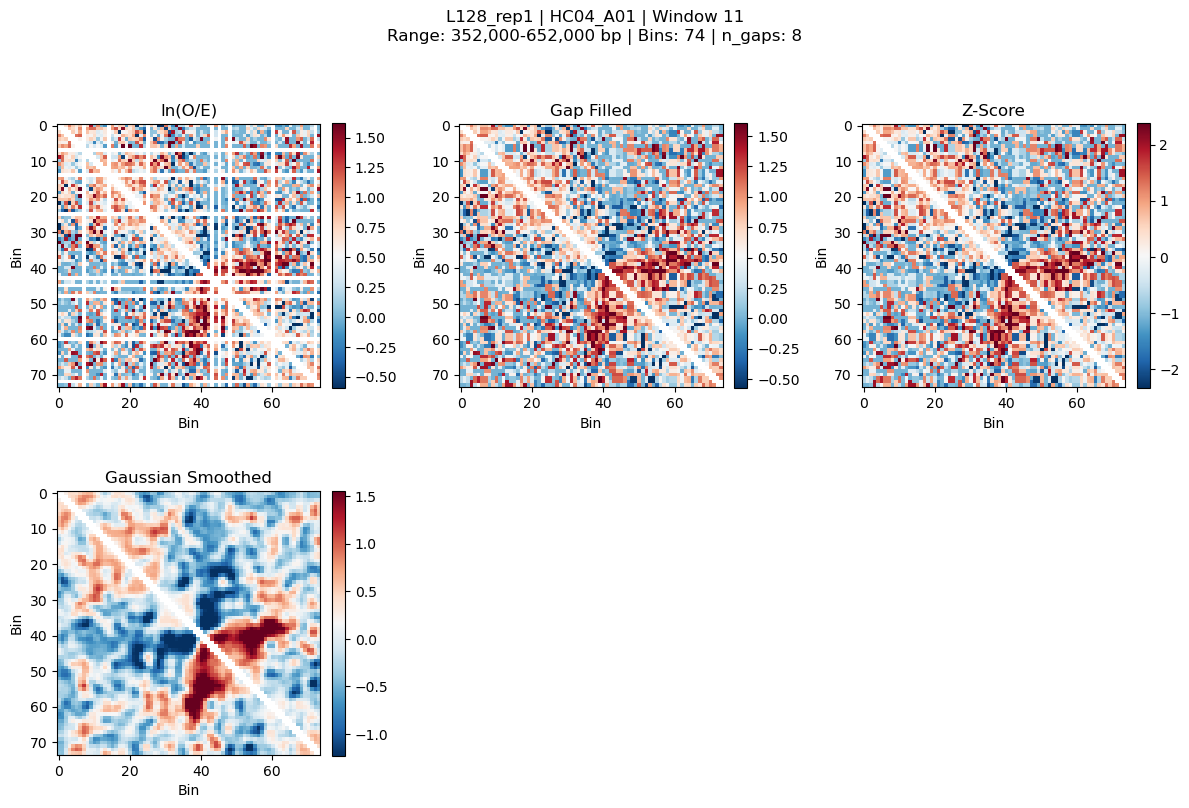

[Done]


In [6]:
def _mask_zero_bins(mat):
    """
    Replace rows and columns that are all zero with NaN.
    A bin with no contacts (all zero in row+col) is masked out.
    Also handles rows/cols that are fully NaN from gap masking.
    """
    mat = mat.astype(np.float64)
    row_sum = np.nansum(np.abs(mat), axis=1)
    zero_mask = row_sum == 0
    if not np.any(zero_mask):
        return mat
    mat[zero_mask, :] = np.nan
    mat[:, zero_mask] = np.nan
    return mat


def plot_all_heatmaps(data, ncols=3):
    """
    Plot all normalization types in a grid. Zero-only and gap bins are masked as NaN.
    """
    data = {k: _mask_zero_bins(v.copy()) for k, v in data.items()}
    order = ['raw', 'iced', 'ln_oe', 'fill_gap', 'zscore', 'gaussian']
    ordered_data = {k: data[k] for k in order if k in data}

    ntypes = len(ordered_data)
    nrows = (ntypes + ncols - 1) // ncols

    fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 4*nrows))
    axes = axes.flatten() if ntypes > 1 else [axes]

    titles = {
        'raw': 'Raw',
        'iced': 'ICE Normalized',
        'ln_oe': 'ln(O/E)',
        'fill_gap': 'Gap Filled',
        'zscore': 'Z-Score',
        'gaussian': 'Gaussian Smoothed',
    }

    cmaps = {
        'raw': 'YlOrRd',
        'iced': 'YlOrRd',
        'ln_oe': 'RdBu_r',
        'fill_gap': 'RdBu_r',
        'zscore': 'RdBu_r',
        'gaussian': 'RdBu_r',
    }

    for idx, (name, mat) in enumerate(ordered_data.items()):
        if idx >= len(axes):
            break

        flat = mat.flatten()
        flat = flat[~np.isnan(flat)]
        if len(flat) > 0:
            vmin, vmax = np.percentile(flat, [2, 98])
        else:
            vmin, vmax = None, None

        plot_data = mat.astype(np.float64)
        im = axes[idx].imshow(plot_data, cmap=cmaps.get(name, 'viridis'),
                               vmin=vmin, vmax=vmax, aspect='equal',
                               interpolation='nearest')
        axes[idx].set_title(titles.get(name, name))
        axes[idx].set_xlabel('Bin')
        axes[idx].set_ylabel('Bin')
        plt.colorbar(im, ax=axes[idx], fraction=0.046, pad=0.04)

    # Hide unused subplots
    for idx in range(ntypes, len(axes)):
        axes[idx].axis('off')

    plt.suptitle(f"{SAMPLE} | {CHROM} | Window {WINDOW_ID}\n"
                 f"Range: {window_info['window_start']:,}-{window_info['window_end']:,} bp | "
                 f"Bins: {mat.shape[0]} | n_gaps: {window_info['n_gaps']}", y=1.02)
    plt.tight_layout()
    return fig


# --- Plot ---
print("[Plot] Rendering heatmaps...")
fig = plot_all_heatmaps(window_data, ncols=3)
plt.show()
print("[Done]")

[OK] 使用窗口 ID: L128_rep1__HC04_A05 window_id=820
     区间: 26,240,000-26,540,000 bp
     bins: 6560-6634 (n=0)
     gaps: 0

[加载] L128_rep1 | HC04_A05 | window 820...
Loaded data types: ['ln_oe', 'fill_gap', 'zscore', 'gaussian']

[绘图] 渲染热图...
[保存] /share/home/xhhuang24/project/PanTE/background_pool/jupyter/L128_rep1__HC04_A05_window_820_heatmap.pdf


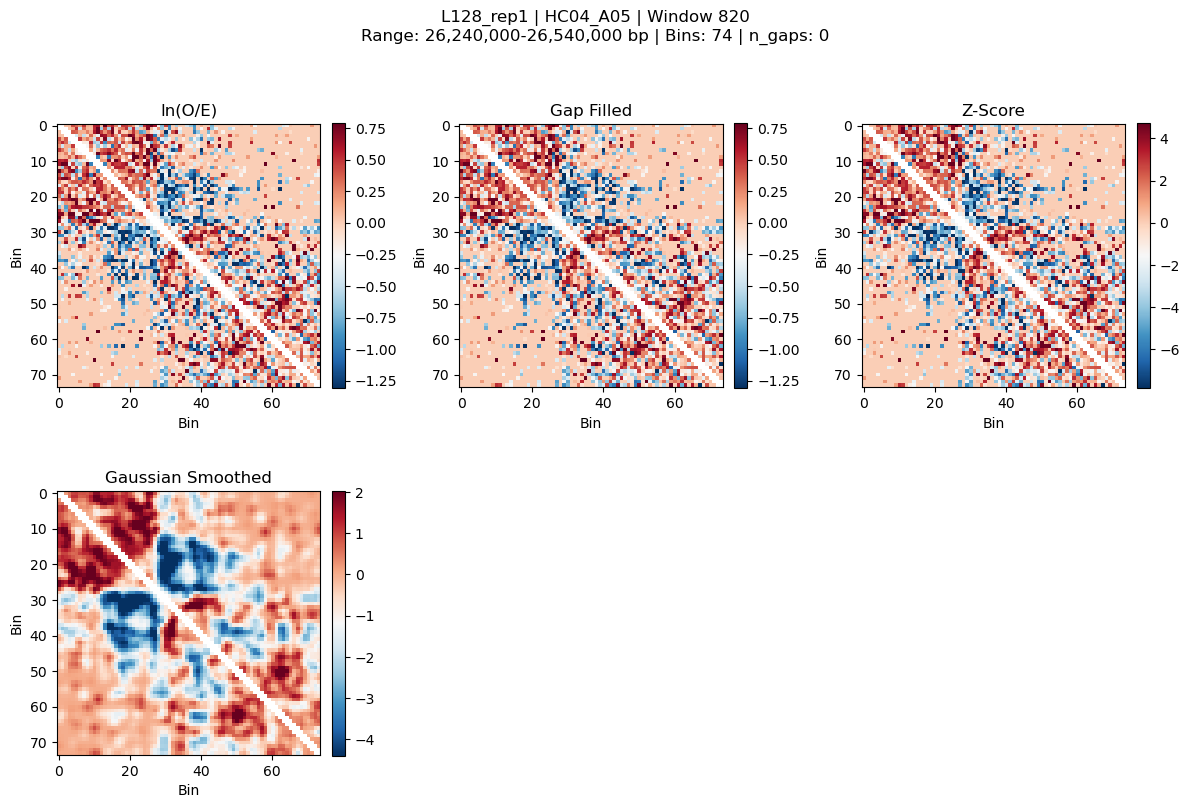

[完成]


In [10]:
# ============================================================
# Quick Window Visualization
# 修改以下参数后直接运行此 cell 即可出图
# ============================================================

# === 修改这里: 窗口参数 ===
# 方式1: 直接使用 WINDOW_ID (推荐)
# SAMPLE = "H1398_rep1"
# CHROM = "HC04_A05"
# WINDOW_ID = 2220              # 直接指定窗口 ID

# SAMPLE = "L134_rep1"
# CHROM = "HC04_A05"
# WINDOW_ID = 2220              # 直接指定窗口 ID


# SAMPLE = "H1398_rep1"
# CHROM = "HC04_D03"
# WINDOW_ID = 1311           # 直接指定窗口 ID
# SAMPLE = "H1398_rep1"
# CHROM = "HC04_A13"
# WINDOW_ID = 2350            # 直接指定窗口 ID

# SAMPLE = "L128_rep1"
# CHROM = "HC04_D11"
# WINDOW_ID = 852  

SAMPLE = "L128_rep1"
CHROM = "HC04_A05"
WINDOW_ID = 820  

# 方式2: 使用基因组坐标 (当 WINDOW_ID 为 None 时启用)
# SAMPLE = "L134_rep1"
# CHROM = "HC04_A05"
# WINDOW_ID = None
# WINDOW_START = 71040000
# WINDOW_END = 71340000


# === 自动处理: 根据 WINDOW_ID 是否为 None 来决定查找方式 ===
sample_chrom = f"{SAMPLE}__{CHROM}"
sample_dir = os.path.join(WORKDIR, OUTDIR, "windows", SAMPLE)
qc_file = os.path.join(sample_dir, f"{sample_chrom}_window_qc.tsv")

if not os.path.exists(qc_file):
    print(f"[ERROR] QC 文件不存在: {qc_file}")
else:
    qc_df = pd.read_csv(qc_file, sep="\t", index_col=0)

    # 如果 WINDOW_ID 是 None，则根据坐标查找
    if WINDOW_ID is None:
        if 'WINDOW_START' not in dir() or WINDOW_START is None:
            print("[ERROR] WINDOW_ID 为 None 时必须设置 WINDOW_START")
            WINDOW_ID = -1
        elif 'WINDOW_END' not in dir() or WINDOW_END is None:
            print("[ERROR] WINDOW_ID 为 None 时必须设置 WINDOW_END")
            WINDOW_ID = -1
        else:
            # 精确匹配窗口
            window_row = qc_df[
                (qc_df['window_start'] == WINDOW_START) & 
                (qc_df['window_end'] == WINDOW_END)
            ]

            if len(window_row) == 0:
                print(f"[WARNING] 精确匹配未找到，尝试模糊匹配...")
                # 模糊匹配：找到包含该区间的窗口
                window_row = qc_df[
                    (qc_df['window_start'] <= WINDOW_START) & 
                    (qc_df['window_end'] >= WINDOW_END)
                ]

            if len(window_row) > 0:
                WINDOW_ID = int(window_row['window_id'].values[0])
                window_info = window_row.iloc[0]
                print(f"[OK] 找到窗口: {sample_chrom} window_id={WINDOW_ID}")
                print(f"     区间: {window_info['window_start']:,}-{window_info['window_end']:,} bp")
                print(f"     bins: {window_info['bin_start']}-{window_info['bin_end']} (n={(window_info['bin_end'] - window_info['bin_start']) // RESOLUTION})")
                print(f"     gaps: {window_info['n_gaps']}")
            else:
                print(f"[ERROR] 未找到窗口: {sample_chrom} {WINDOW_START}-{WINDOW_END}")
                WINDOW_ID = -1
    else:
        # 直接使用 WINDOW_ID
        if WINDOW_ID < len(qc_df):
            window_info = qc_df.iloc[WINDOW_ID]
            print(f"[OK] 使用窗口 ID: {sample_chrom} window_id={WINDOW_ID}")
            print(f"     区间: {window_info['window_start']:,}-{window_info['window_end']:,} bp")
            print(f"     bins: {window_info['bin_start']}-{window_info['bin_end']} (n={(window_info['bin_end'] - window_info['bin_start']) // RESOLUTION})")
            print(f"     gaps: {window_info['n_gaps']}")
        else:
            print(f"[ERROR] WINDOW_ID={WINDOW_ID} 超出范围 (最大: {len(qc_df)-1})")
            WINDOW_ID = -1


# === 加载数据并绘图 ===
if WINDOW_ID >= 0:
    print(f"\n[加载] {SAMPLE} | {CHROM} | window {WINDOW_ID}...")

    # 复用已有的 load_window_data 函数
    window_data = load_window_data(SAMPLE, CHROM, WINDOW_ID)

    print(f"Loaded data types: {list(window_data.keys())}")

    # 复用已有的 plot_all_heatmaps 函数
    print("\n[绘图] 渲染热图...")
    fig = plot_all_heatmaps(window_data, ncols=3)

    # 保存图片
    out_dir = "/share/home/xhhuang24/project/PanTE/background_pool/jupyter"
    fig_path = os.path.join(out_dir, f"{SAMPLE}__{CHROM}_window_{WINDOW_ID}_heatmap.pdf")
    # fig.savefig(fig_path)
    print(f"[保存] {fig_path}")

    plt.show()
    print("[完成]")
else:
    print("[跳过] 请检查参数是否正确")


In [8]:
import sys
sys.path.insert(0, '/share/home/xhhuang24/project/PanTE/background_pool/scripts')
from detect_internal_breakpoint import detect_internal_breakpoint
import h5py
import pandas as pd
import numpy as np

# Test window: L134_rep1, HC04_A05, window 2220
SAMPLE = "L134_rep1"
CHROM = "HC04_A05"
WINDOW_ID = 2220
RESOLUTION = 4000

# Load ln_oe matrix from HDF5
sample_chrom = f"{SAMPLE}__{CHROM}"
sample_dir = f"/share/home/xhhuang24/project/PanTE/background_pool/results/windows/{SAMPLE}"
h5_file = f"{sample_dir}/{sample_chrom}_ln_oe.h5"
window_key = f"w{WINDOW_ID:06d}"

print(f"Loading from: {h5_file}")

with h5py.File(h5_file, 'r') as f:
    matrix = f[window_key]['matrix'][:]
    print(f"Matrix shape: {matrix.shape}")

# Get window coordinates from QC file
qc_file = f"{sample_dir}/{sample_chrom}_window_qc.tsv"
qc_df = pd.read_csv(qc_file, sep="\t", index_col=0)
window_info = qc_df.iloc[WINDOW_ID]
bin_start = int(window_info['bin_start'])
window_start = bin_start * RESOLUTION

print(f"Window start: {window_start} bp")
print(f"Window end: {int(window_info['bin_end']) * RESOLUTION} bp")

# Detect breakpoint
result = detect_internal_breakpoint(
    matrix=matrix,
    bin_size=RESOLUTION,
    matrix_mode="lnoe",
    window_start=window_start,
)

print("\n=== Breakpoint Detection Result ===")
print(f"is_abnormal: {result['is_abnormal']}")
print(f"best_K: {result['best_K']}")
print(f"best_K_bp: {result['best_K_bp']}")
print(f"total_score: {result['total_score']:.4f}")
print(f"diag_drop: {result['diag_drop']:.4f}")
print(f"block_diff: {result['block_diff']:.4f}")
print(f"status: {result['status']}")
print(f"message: {result['message']}")

ModuleNotFoundError: No module named 'detect_internal_breakpoint'